In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 100)
sns.set_theme(style="whitegrid")

FINDINGS = Path("findings.md")
channels = Path("../data/channels.parquet")
clips = Path("../data/clips.parquet")
games = Path("../data/games.parquet")

chdf = pd.read_parquet(channels)
cdf = pd.read_parquet(clips)
gdf = pd.read_parquet(games)

# make sure no personal data is present for GDPR compliance
# check that these columns should already have been removed in previous notebook:
chdf_personal_columns=["broadcaster_login", "broadcaster_name"]
cdf_personal_columns=["creator_id", "broadcaster_name", "creator_name"]

for col in chdf_personal_columns:
    if col in chdf.columns:
        print(f"Warning: Personal data column '{col}' found in channels dataframe.")
for col in cdf_personal_columns:
    if col in cdf.columns:
        print(f"Warning: Personal data column '{col}' found in clips dataframe.")

print("channels : ", chdf.shape[0], "rows,", chdf.shape[1], "columns")
print("clips : ", cdf.shape[0], "rows,", cdf.shape[1], "columns")
print("games : ", gdf.shape[0], "rows,", gdf.shape[1], "columns")

channels :  877 rows, 9 columns
clips :  1992 rows, 14 columns
games :  20 rows, 4 columns


### Transforming the data

In [15]:
# remove uncessary columns
cdf = cdf.drop(columns=["thumbnail_url", "url", "embed_url"])
gdf = gdf.drop(columns=["box_art_url"])

# now we transform variables to proper types
chdf['broadcaster_id'] = pd.to_numeric(chdf["broadcaster_id"], errors="coerce").astype("Int64")
chdf['game_id'] = pd.to_numeric(chdf["game_id"], errors="coerce").astype("Int64")
chdf['game_name'] = chdf['game_name'].astype("string")
chdf['broadcaster_language'] = chdf['broadcaster_language'].astype("string")
chdf['title'] = chdf['title'].astype("string")
# Here we parse the tags column, which is a comma-separated string of tags, into a list of strings.
chdf["tags"] = chdf["tags"].astype("string")
chdf['tags'] = chdf['tags'].str.split(",").apply(lambda x: [item.strip() for item in x] if isinstance(x, list) else x)

# parse labels column, which is a comma-separated string of labels, into a list of strings.
chdf['content_classification_labels'] = chdf['content_classification_labels'].astype("string")
chdf['content_classification_labels'] = chdf['content_classification_labels'].str.split(",").apply(lambda x: [item.strip() for item in x] if isinstance(x, list) else x)


# Clip IDs are strings
cdf["id"] = cdf["id"].astype("string")
cdf["broadcaster_id"] = pd.to_numeric(cdf["broadcaster_id"], errors="coerce").astype("Int64")
cdf["video_id"] = pd.to_numeric(cdf["video_id"], errors="coerce").astype("Int64")
cdf["game_id"] = pd.to_numeric(cdf["game_id"], errors="coerce").astype("Int64")
cdf["language"] = cdf["language"].astype("string")
cdf["title"] = cdf["title"].astype("string")
# Quantitative / Numerical features
cdf["view_count"] = pd.to_numeric(cdf["view_count"], errors="coerce").astype("Int64")
cdf["duration"] = pd.to_numeric(cdf["duration"], errors="coerce").astype("Float64")
# vod_offset is in seconds; Int64 accommodates clips where VOD no longer exists (null)
cdf["vod_offset"] = pd.to_numeric(cdf["vod_offset"], errors="coerce").astype("Int64")
cdf["created_at"] = pd.to_datetime(cdf["created_at"], utc=True)
cdf["is_featured"] = cdf["is_featured"].astype("boolean")

gdf["id"] = pd.to_numeric(gdf["id"], errors="coerce").astype("Int64")
gdf["name"] = gdf["name"].astype("string")
gdf["igdb_id"] = pd.to_numeric(gdf["igdb_id"], errors="coerce").astype("Int64")


print("channels dtypes:")
print(chdf.dtypes.to_string())
print("\nclips dtypes:")
print(cdf.dtypes.to_string())
print("\ngames dtypes:")
print(gdf.dtypes.to_string())

channels dtypes:
broadcaster_id                            Int64
broadcaster_language             string[python]
game_id                                   Int64
game_name                        string[python]
title                            string[python]
delay                                     int64
tags                                     object
content_classification_labels            object
is_branded_content                         bool

clips dtypes:
id                     string[python]
broadcaster_id                  Int64
video_id                        Int64
game_id                         Int64
language               string[python]
title                  string[python]
view_count                      Int64
created_at        datetime64[ns, UTC]
duration                      Float64
vod_offset                      Int64
is_featured                   boolean

games dtypes:
id                  Int64
name       string[python]
igdb_id             Int64


In [16]:
# estimators of quantitative vars
print("delay descriptors : ", chdf['delay'].describe().round(2).to_string())
print("view_count descriptors : ", cdf['view_count'].describe().round(2).to_string())
print("duration descriptors : ", cdf['duration'].describe().round(2).to_string())
print("vod_offset descriptors : ", cdf['vod_offset'].describe().round(2).to_string())



delay descriptors :  count    877.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
view_count descriptors :  count      1992.0
mean      8266.01
std      14121.44
min          80.0
25%        936.75
50%        3672.5
75%       9748.25
max      215980.0
duration descriptors :  count    1992.0
mean      26.52
std       17.16
min         4.9
25%        11.5
50%        24.0
75%        34.6
max        60.0
vod_offset descriptors :  count      1515.0
mean     13728.24
std      17368.14
min          93.0
25%        4151.0
50%        9355.0
75%       17111.5
max      167974.0


we see that delay is 0 for all. This isn't very interesting, we will remove it from the df:

In [17]:
chdf = chdf.drop(columns =['delay'])

### Identifying collumns with missing values : 

In [18]:
for(df, name) in [(chdf, "channels"), (cdf, "clips"), (gdf, "games")]:
    print(f"\n{name} missing values:")
    missing = df.isna().sum()
    missing = missing[missing > 0]
    percentage_missing = (missing / df.shape[0]) * 100
    print(missing.to_string(),"\n\nPercentage of missing values:\n",  percentage_missing.round(2).to_string())



channels missing values:
game_id    5 

Percentage of missing values:
 game_id    0.57

clips missing values:
video_id      477
vod_offset    477 

Percentage of missing values:
 video_id      23.95
vod_offset    23.95

games missing values:
igdb_id    6 

Percentage of missing values:
 igdb_id    30.0


we see that igdb_id for game df, as well as video_id and vod_offset for clips df, are missing at high percentage. Furthermore, video_id and vod_offset are missing at the same rate, leading us to wonder if this is linked.

we should consider investigating the link :

In [19]:
both_missing = cdf["video_id"].isna() & cdf["vod_offset"].isna()
one_missing = cdf["video_id"].isna() ^ cdf["vod_offset"].isna()

print(f"Rows where both are missing: {both_missing.sum()}")
print(f"Rows where only one is missing: {one_missing.sum()}")

Rows where both are missing: 477
Rows where only one is missing: 0


this confirms our intuition. After some research, we learn that in Twitch's architecture, if a broadcaster does not archive past broadcasts (VODs) or if the 14–60 day VOD retention window expires, Twitch drops both the source video_id and the vod_offset simultaneously, while keeping the clip itself.

we also found that the missing igdb_id is for linking to Internet Game Database, to get game metadata. This is outside of our scope.

In any case these columns are not interesting to use. We also notice that clip id collumn is a randomly generate string of no interest to us. We can delete them :

In [20]:
cdf = cdf.drop(columns=["video_id", "vod_offset", "id"])
gdf = gdf.drop(columns=["igdb_id"])

## Looking for impossible, extreme, ambiguous values

In [21]:
impossible_clips = (
    (cdf["duration"] <= 0)                      # Clip has zero or negative duration
    | (cdf["duration"] > 60)                   #  Twitch clip minimum length is 5s, max is 60
    | (cdf["view_count"] < 0)                   # no egative views
    | (cdf["created_at"] > pd.Timestamp.now(tz="UTC"))  # Future timestamps or timestaps that are too old
    | (cdf["created_at"] < pd.Timestamp("2015-01-01", tz="UTC"))  # Timestamps that are too old
)

ambiguous_clips = (
    (cdf["view_count"] == 0)                    # Zero views (dead clip or tracking delay)
    | (cdf["duration"] < 5.0)                   #  Twitch clip minimum length is 5s, max is 60
    | (cdf["view_count"] > 1000000)           # Extreme outlier
)

print(f"Impossible rows  : {impossible_clips.sum():,} ({impossible_clips.mean():.2%})")
print(f"Ambiguous rows   : {ambiguous_clips.sum():,} ({ambiguous_clips.mean():.2%})")
print(f"Clean rows       : {(~(impossible_clips | ambiguous_clips)).sum():,} ({(~(impossible_clips | ambiguous_clips)).mean():.2%})\n")

if ambiguous_clips.any():
    print("Sample ambiguous clips:")
    print(cdf.loc[ambiguous_clips, ["title", "duration", "view_count", "duration"]].head())

Impossible rows  : 0 (0.00%)
Ambiguous rows   : 50 (2.51%)
Clean rows       : 1,942 (97.49%)

Sample ambiguous clips:
                 title  duration  view_count  duration
4     CLAIM THAT WOMAN       4.9      101022       4.9
11               зачем       4.9       69135       4.9
18                オカズ🦶       4.9       56772       4.9
19       he just nuted       4.9       54744       4.9
33  i am not good girl       4.9       39859       4.9


No impossible data. We see that the ambiguous probelem is a duration of 4.9. This seems ok, because min duration is 5 so it's a small error we don't care about.

This means our data frames are clean!

## temporal patterns

First clip created at : 2026-09-01 00:09:12+00:00
Last clip created at  : 2026-09-30 23:45:15+00:00


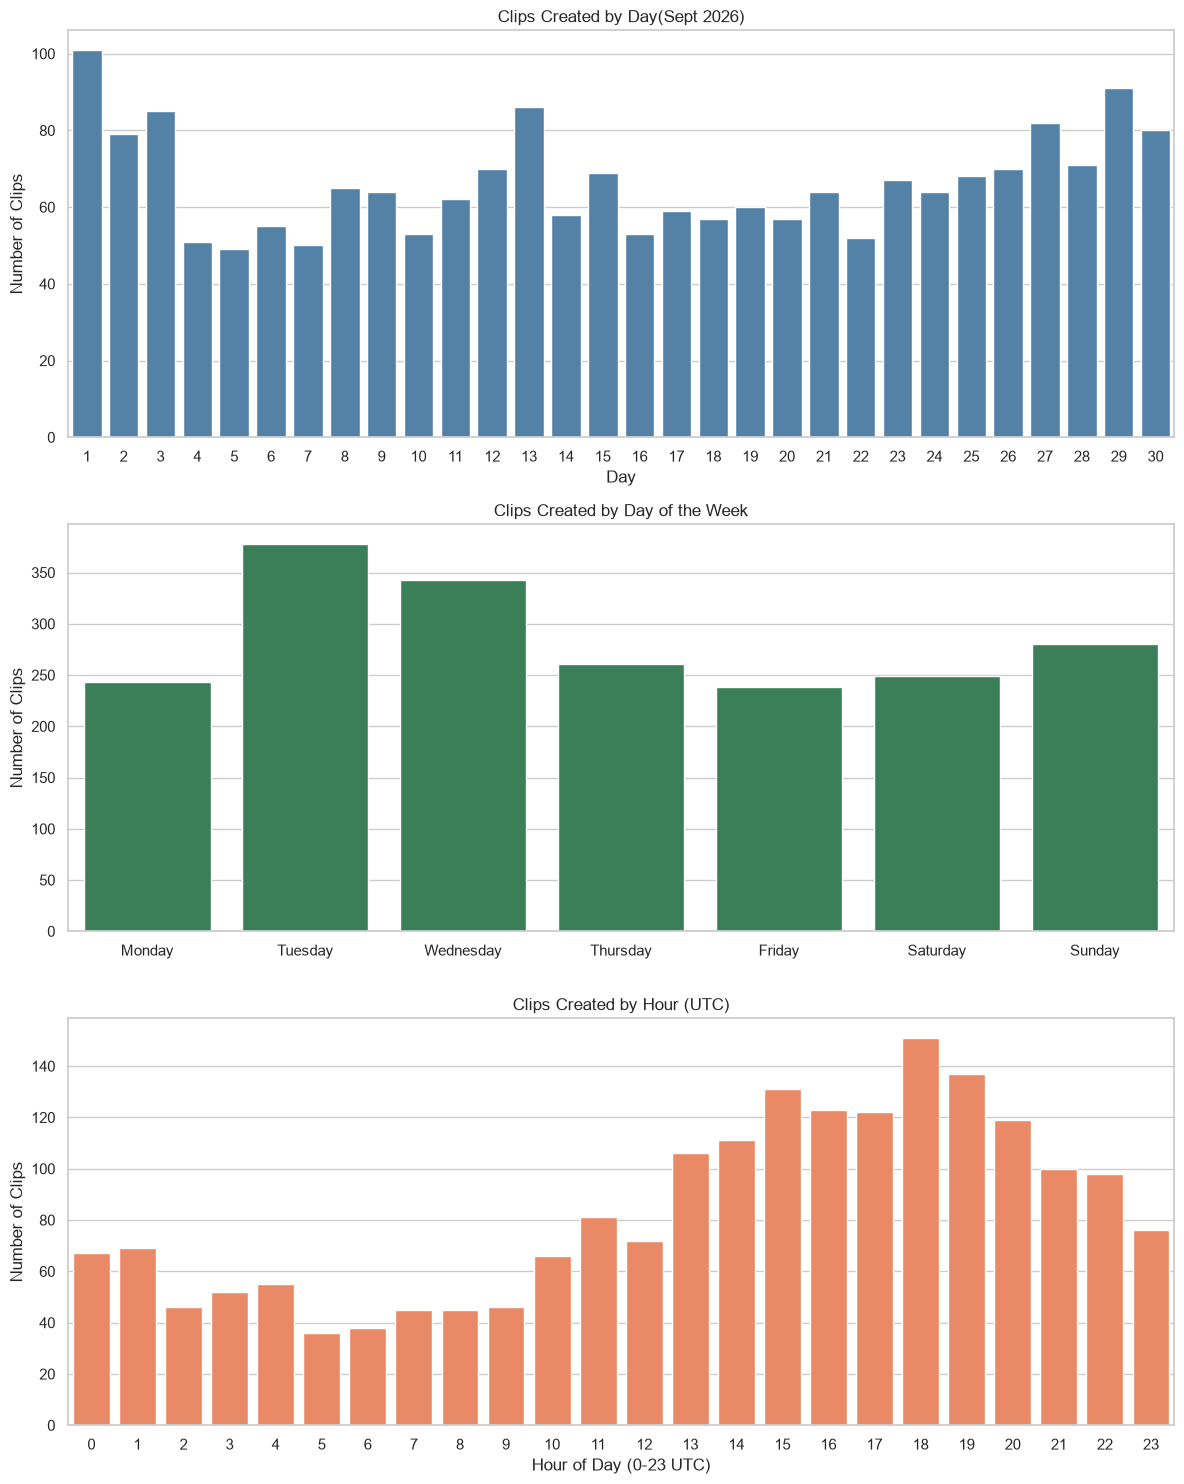

In [22]:
# lets make sure we have the correct range:
print("First clip created at :", cdf["created_at"].min())
print("Last clip created at  :", cdf["created_at"].max())

cdf['day_of_month'] = cdf['created_at'].dt.day
cdf['day_of_week'] = cdf['created_at'].dt.day_name()
cdf['hour_of_day'] = cdf['created_at'].dt.hour

fig, axes = plt.subplots(3, 1, figsize=(12, 15))
# plot daily
sns.countplot(data=cdf, x='day_of_month', color='steelblue', ax=axes[0])
axes[0].set_title('Clips Created by Day(Sept 2026)')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Number of Clips')

# plot weekly
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=cdf, x='day_of_week', order=days_order, color='seagreen', ax=axes[1])
axes[1].set_title('Clips Created by Day of the Week')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Clips')

# plot hourly
sns.countplot(data=cdf, x='hour_of_day', color='coral', ax=axes[2])
axes[2].set_title('Clips Created by Hour (UTC)')
axes[2].set_xlabel('Hour of Day (0-23 UTC)')
axes[2].set_ylabel('Number of Clips')

plt.tight_layout()
plt.show()

**Range covered:** 2026-09-01T00:09:12+00:00 to 2026-09-30T23:45:15Z. This makes sense, its what we asked for.

**Gaps:** No gaps, we visualized this.

**Cycles:** Tuesday, then wedsnday, are when most clips get made. By hour, big uptick starting at 10 untill 18, then bell curve trends downwards until midnight. High activity at start of month.

**Timezone:** Timestamps are in UTC because parsing the `created_at` column with `pd.to_datetime(..., utc=True)`.


### Exploring qualitative data

We have many qualitative variables including tags, title, content classification, is branded_content

Observations of raw data: 
- channel tags seem to allways include language(s), sometimes many languages
- content_classification labels of few categories, sometimes multiple labels

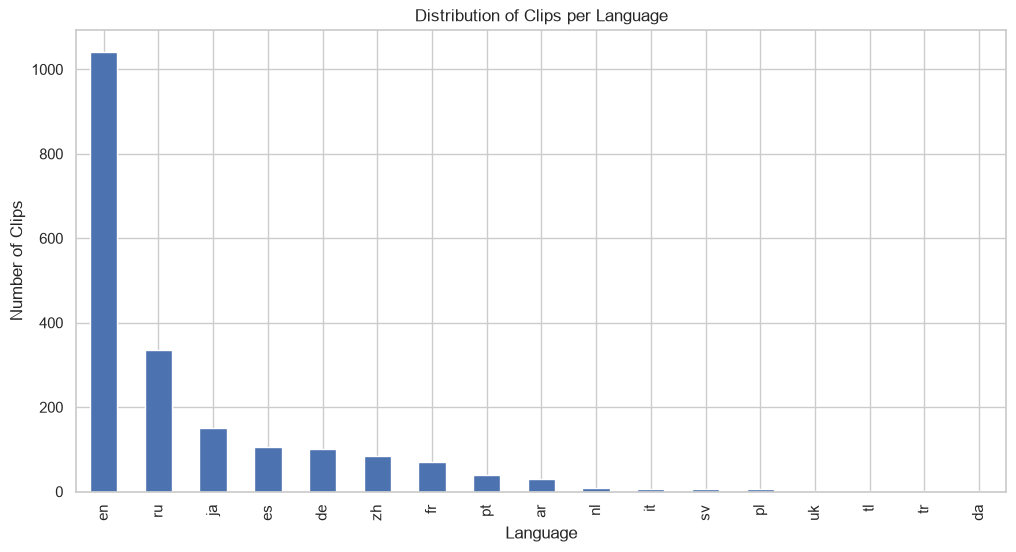

Percentage of 'ru' rows that also have 'Русский' tag: 99.22% (Count: 128/129)
Percentage of 'es' rows that also have 'Español' tag: 100.00% (Count: 48/48)
Percentage of 'ja' rows that also have '日本語' tag: 98.65% (Count: 73/74)
Percentage of 'de' rows that also have 'Deutsch' tag: 100.00% (Count: 49/49)
Percentage of 'en' rows that also have 'English' tag: 97.93% (Count: 426/435)
Percentage of 'fr' rows that also have 'Français' tag: 100.00% (Count: 40/40)
Unique tags found: 588


In [23]:
# visualized dirtibution of clips per language
plt.figure(figsize=(12, 6))
cdf["language"].value_counts().plot(kind="bar")
plt.title("Distribution of Clips per Language")
plt.xlabel("Language")
plt.ylabel("Number of Clips")
plt.show()


# investigate link between language and tags en, ru, es, ja, de
language_mappings = {
    'ru': 'Русский',
    'es': 'Español',
    'ja': '日本語',
    'de': 'Deutsch',
    'en': 'English',
    'fr': 'Français',
}

for lang_code, tag_name in language_mappings.items():
    # 1. Check for the specific language tag
    has_tag = chdf['tags'].astype(str).str.contains(f"'{tag_name}'", regex=False, na=False)
    
    # 2. Check for the specific broadcaster language code
    has_lang = chdf['broadcaster_language'].astype(str).str.strip().str.lower() == lang_code
    
    total_lang_rows = has_lang.sum()
    
    # 3. Calculate and print, ensuring we don't divide by zero
    if total_lang_rows > 0:
        count = (has_tag & has_lang).sum()
        percentage = (count / total_lang_rows) * 100
        print(f"Percentage of '{lang_code}' rows that also have '{tag_name}' tag: {percentage:.2f}% (Count: {count}/{total_lang_rows})")
    else:
        print(f"No rows found for language code '{lang_code}'.")

# calculate number of unique tags
all_tags = chdf['tags'].explode()
tag_counts = all_tags.value_counts()
print("Unique tags found:", tag_counts.shape[0])


we confirm that almost all channels have a tag that match language. We could remove tags that are related to language.


We also want to see what distribution of branded content is like per view, as well as game view distribution :

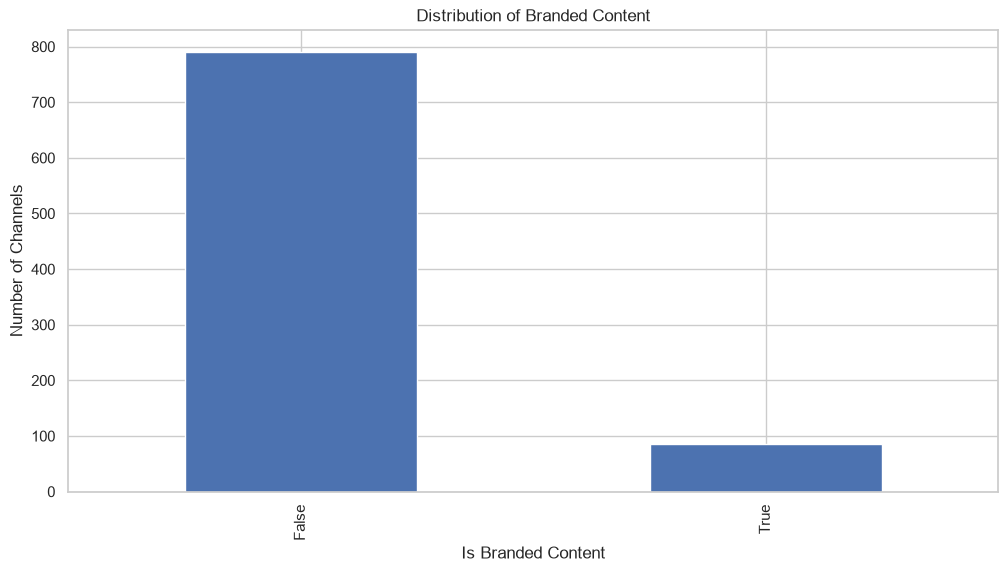

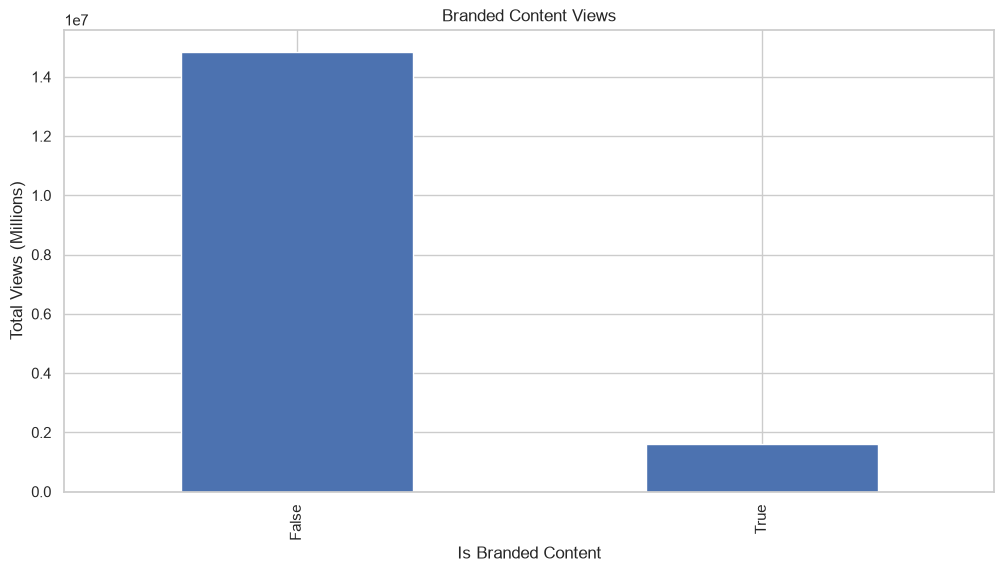

In [33]:
# branded content histogram

branded_content_counts = chdf['is_branded_content'].explode().value_counts()

plt.figure(figsize=(12, 6))
branded_content_counts.plot(kind="bar")
plt.title("Distribution of Branded Content")
plt.xlabel("Is Branded Content")
plt.ylabel("Number of Channels")
plt.show()

# branded content per view
# join channels and clips dataframes on broadcaster_id
merged_df = pd.merge(cdf, chdf, on='broadcaster_id', how='left')
branded_content_views = merged_df.groupby('is_branded_content')['view_count'].sum()

plt.figure(figsize=(12, 6))
branded_content_views.plot(kind="bar")
plt.title("Branded Content Views")
plt.xlabel("Is Branded Content")
plt.ylabel("Total Views (Millions)")
plt.show()



### Checking for duplicates
Next lets check that each broadcater is represented once in channels:

In [26]:
# check for any duplicate broadcaster_id in channels dataframe
duplicate_broadcaster_ids = chdf[chdf.duplicated(subset='broadcaster_id', keep=False)]
if not duplicate_broadcaster_ids.empty:
    print("Duplicate broadcaster_id found in channels dataframe:")
    print(duplicate_broadcaster_ids[['broadcaster_id', 'title', 'game_name']])
else:
    print("No duplicate broadcaster_id found in channels dataframe.")

No duplicate broadcaster_id found in channels dataframe.


We do the same for games:

In [ ]:
# check for any duplicate broadcaster_id in channels dataframe
duplicate_game_ids = gdf[gdf.duplicated(subset='id', keep=False)]
if not duplicate_game_ids.empty:
    print("Duplicate game_id found in games gdf:")
    print(duplicate_game_ids[['id', 'name']])
else:
    print("No duplicate game_id found in games gdf.")

No duplicate game_id found in games dataframe.


### Save cleaned data

In [25]:
CLEAN_DATA_DIR = Path.cwd().parent / "data/clean/"
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

# define file paths
clean_games_path = CLEAN_DATA_DIR / "games_cleaned.parquet"
clean_clips_path = CLEAN_DATA_DIR / "clips_cleaned.parquet"
clean_channels_path = CLEAN_DATA_DIR / "channels_cleaned.parquet"

# save parquet files locally
gdf.to_parquet(clean_games_path, index=False)
cdf.to_parquet(clean_clips_path, index=False)
chdf.to_parquet(clean_channels_path, index=False)